# 03. Exploring demand

**Where we are:** notebook 02 built clean half-hourly tables and measured NESO's forecast
(MAE about 689 MW from June 2024). Its errors are largest at midday and growing.

**What this notebook does:** looks at the patterns a forecast has to capture: the long-term
trend, the yearly, weekly and daily cycles, holidays, Christmas, the 2020 lockdown, and the
effect of embedded solar and wind. Each finding ends in a decision for the model.

**Why only data before June 2024:** the final test window starts on 2024-06-01. If I explored
the test period too, what I saw there could shape the model, and the test score would look
better than it should. So everything here stops at 2024-05-31.

**Background reading**
- [Forecasting: Principles and Practice, section 2.3, time series patterns](https://otexts.com/fpp3/tspatterns.html)
- [Duck curve](https://en.wikipedia.org/wiki/Duck_curve): how solar reshapes daily demand


## Step 1. Set up and load

**What:** load `demand.parquet` from notebook 02 and add local-time columns.

**Why local time:** people switch the kettle on by the clock on the wall, not by UTC. Daily
patterns line up in local time, so calendar features use it. The UTC timestamp stays as the key.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROCESSED = Path("../data/processed")
TEST_START = pd.Timestamp("2024-06-01", tz="Europe/London")

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e4e0",
    "lines.linewidth": 2,
})

demand = pd.read_parquet(PROCESSED / "demand.parquet")
demand = demand[demand["start_utc"] < TEST_START].copy()

local = demand["start_utc"].dt.tz_convert("Europe/London")
demand["date"] = pd.to_datetime(demand["Date"])
demand["year"] = demand["date"].dt.year
demand["month"] = demand["date"].dt.month
demand["weekday"] = demand["date"].dt.dayofweek
demand["local_hour"] = local.dt.hour + local.dt.minute / 60
demand["underlying"] = demand["ND"] + demand["EMBEDDED_SOLAR_GENERATION"] + demand["EMBEDDED_WIND_GENERATION"]

daily = demand.groupby("date").agg(ND=("ND", "mean"), underlying=("underlying", "mean")).asfreq("D")
print(demand.shape, demand["Date"].min(), "to", demand["Date"].max())


(112462, 30) 2018-01-01 to 2024-05-31


## Step 2. Long-term trend

**What:** a rolling 365-day mean of `ND`, and of "underlying" demand, which adds the estimated
embedded solar and wind back in.

**Why a rolling year:** a calendar-year mean is distorted by part years (2024 here only runs to
May, mostly winter). A 365-day window always holds one of each season.

**Why underlying demand:** `ND` only counts what the transmission network carries. Embedded
generation is used locally and never shows up in it. Adding it back separates "people use less
electricity" from "more of it is generated locally".


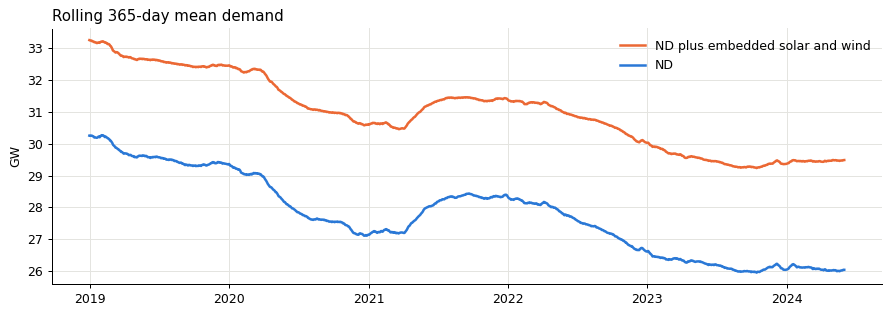

                 ND  underlying
date                           
2018-12-31  30247.0     33235.0
2024-05-31  26051.0     29484.0


In [2]:
rolling = daily.rolling(365, min_periods=365).mean().dropna()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(rolling.index, rolling["underlying"] / 1000, color=ORANGE, label="ND plus embedded solar and wind")
ax.plot(rolling.index, rolling["ND"] / 1000, color=BLUE, label="ND")
ax.set_ylabel("GW")
ax.set_title("Rolling 365-day mean demand", loc="left")
ax.legend(loc="upper right", frameon=False)
fig.tight_layout()
plt.show()

print(rolling.iloc[[0, -1]].round(0).to_string())


**Found:**

- The rolling yearly mean of `ND` fell from 30.2 GW (year to end 2018) to 26.1 GW (year to May
  2024). Underlying demand fell from 33.2 GW to 29.5 GW.
- So embedded generation explains only a small part of the fall (about 0.4 of the 4.1 GW, going by
  NESO's estimates). Most of it is lower consumption.
- The fall is not smooth: a dip in 2020 (the lockdown), a recovery in 2021, a steady fall
  through 2022 into 2023, which lines up in time with the jump in energy prices, and a flat
  stretch since mid-2023.

**Decision:** the demand level shifts over the years, so a model fitted on 2018 must not assume
2018 levels. Recent demand lags (Step 11) carry the current level into the forecast. Day 6 will
also compare training on all years against training on recent years only.


## Step 3. Yearly cycle

**What:** the typical daily mean demand for each week of the year, across all years.

**Why:** heating and lighting drive demand up in winter. This cycle is the largest pattern in
the data. Most of it is temperature and daylight, which the weather features on Day 4 should
explain better than a calendar can.


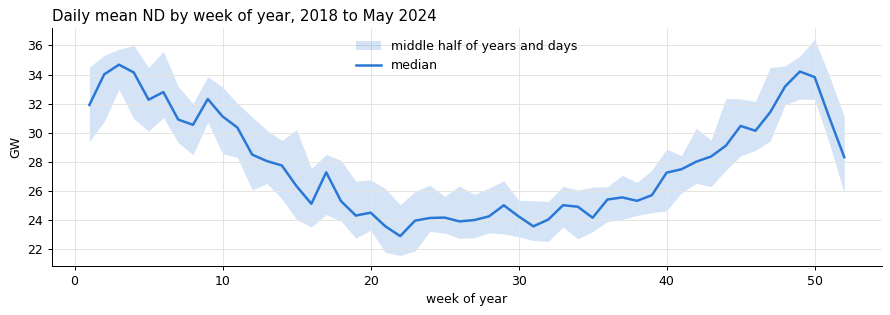

winter (weeks 1-6) to summer (weeks 27-32) ratio: 1.38


In [3]:
week = daily.index.isocalendar().week.clip(upper=52)
by_week = daily["ND"].groupby(week.values).describe()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.fill_between(by_week.index, by_week["25%"] / 1000, by_week["75%"] / 1000, color=BLUE, alpha=0.2,
                linewidth=0, label="middle half of years and days")
ax.plot(by_week.index, by_week["50%"] / 1000, color=BLUE, label="median")
ax.set_xlabel("week of year")
ax.set_ylabel("GW")
ax.set_title("Daily mean ND by week of year, 2018 to May 2024", loc="left")
ax.legend(loc="upper center", frameon=False)
fig.tight_layout()
plt.show()

print("winter (weeks 1-6) to summer (weeks 27-32) ratio:",
      round(by_week.loc[1:6, "50%"].mean() / by_week.loc[27:32, "50%"].mean(), 2))


**Found:** winter demand (weeks 1 to 6) is about 38% higher than midsummer (weeks 27 to 32).
The lowest weeks are late May and early June, around 23 GW, when days are long and heating is
off. The ups and downs between spring weeks come partly from Easter moving between weeks and
partly from small samples (six or seven years per week). The drop in week 52 is Christmas.

**Decision:** temperature and daylight features (Day 4) should carry most of this. Day of year
can stay in as a calendar feature for what weather does not explain.


## Step 4. Weekly cycle

**What:** mean demand on each day of the week, relative to the average weekday.

**Why:** offices, shops and factories run on a weekly schedule, so weekends look different.
This tells us whether "weekday or weekend" is enough, or whether each day needs its own label.


In [4]:
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_day = daily["ND"].groupby(daily.index.dayofweek).mean()
relative = (by_day / by_day.loc[0:4].mean()).round(3)
relative.index = day_names
relative.to_frame("relative to mean weekday")


,relative to mean weekday
Mon,0.988
Tue,1.009
Wed,1.009
Thu,1.008
Fri,0.986
Sat,0.890
Sun,0.875


**Found:** Tuesday to Thursday are almost identical. Monday and Friday sit about 1.3% lower,
Saturday 11% lower and Sunday 12.5% lower.

**Decision:** use day of week as a seven-level feature, not just a weekend flag.


## Step 5. Daily profile and how it has changed

**What:** the average half-hourly shape of a weekday in summer and in winter, in 2018 and 2023
(the first and last full years before the test window).

**Why:** the daily shape is what the model has to reproduce period by period. Comparing two
years shows whether the shape is stable or drifting.


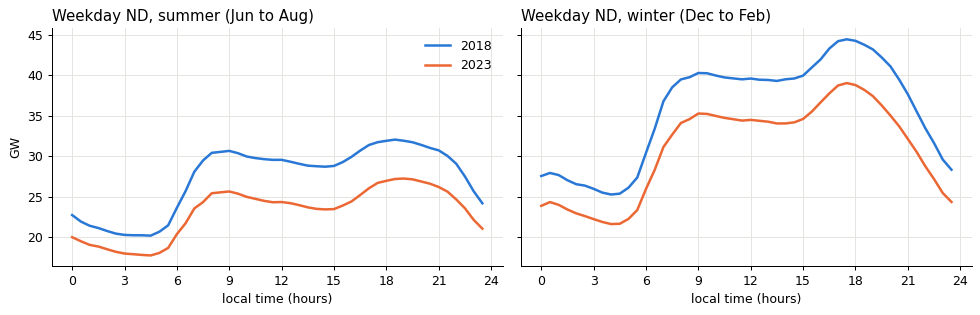

summer weekday ND (MW) at 05:00, 13:00 and 18:00
local_hour     5.0      13.0     18.0
year                                 
2018        20674.0  29053.0  31885.0
2019        19972.0  28345.0  30941.0
2020        18470.0  26234.0  29050.0
2021        19764.0  27308.0  30285.0
2022        19059.0  25168.0  28227.0
2023        18058.0  23954.0  26948.0


In [5]:
weekday_rows = demand[demand["weekday"] < 5]
seasons = {"summer (Jun to Aug)": [6, 7, 8], "winter (Dec to Feb)": [12, 1, 2]}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (title, months) in zip(axes, seasons.items()):
    for year, color in [(2018, BLUE), (2023, ORANGE)]:
        rows = weekday_rows[(weekday_rows["year"] == year) & weekday_rows["month"].isin(months)]
        profile = rows.groupby("local_hour")["ND"].mean() / 1000
        ax.plot(profile.index, profile.values, color=color, label=str(year))
    ax.set_title(f"Weekday ND, {title}", loc="left")
    ax.set_xticks(range(0, 25, 3))
    ax.set_xlabel("local time (hours)")
axes[0].set_ylabel("GW")
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

summer = weekday_rows[weekday_rows["month"].isin([6, 7, 8])]
table = summer.pivot_table(index="year", columns="local_hour", values="ND", aggfunc="mean")
print("summer weekday ND (MW) at 05:00, 13:00 and 18:00")
print(table[[5.0, 13.0, 18.0]].round(0).to_string())


**Found:**

- **Summer weekday:** between 2018 and 2023, demand at 13:00 fell by 5.1 GW (29.1 to 24.0 GW,
  18%), against 2.6 GW at 05:00 (13%). By 2023 there is a clear dip at midday, below both the
  morning and the evening. This is the duck curve: embedded solar removes demand from the
  middle of the day.
- **Winter weekday:** the shape barely changed, but the whole curve dropped by about 4 to 5 GW.
  The evening peak around 17:30 is still the highest point of the year.
- So the daily shape itself drifts, and it drifts most in summer at midday, where notebook 02
  found NESO's largest errors.

**Decision:** the model needs time of day combined with solar information, not a fixed daily
profile. A tree model with time of day and solar features can learn that combination.

**Further reading:** [Duck curve](https://en.wikipedia.org/wiki/Duck_curve)


## Step 6. Bank holidays

**What:** compare demand on each bank holiday with the same weekday one week before and one
week after.

**Why that reference:** comparing with neighbouring weeks removes most of the season and the
weekday effect. It is not perfect, because weather differs from week to week, but it shows the
size of the holiday effect.

**Which holidays:** England and Wales. They carry about 91% of `ND` (from the
`ENGLAND_WALES_DEMAND` column), and Scotland's extra holidays (2 January, St Andrew's Day, an
earlier August holiday) are a small share of the total. The `holidays` package covers 2018,
which the gov.uk feed does not.

**Further reading:** [UK bank holidays (gov.uk)](https://www.gov.uk/bank-holidays),
[`holidays` package](https://holidays.readthedocs.io/)


In [6]:
import holidays

share = (demand["ENGLAND_WALES_DEMAND"] / demand["ND"])[demand["ENGLAND_WALES_DEMAND"] > 0]
print(f"England and Wales share of ND: {share.median():.3f}")

bank_holidays = holidays.UK(subdiv="ENG", years=range(2018, 2025))
holiday_dates = pd.to_datetime([d for d in bank_holidays if pd.Timestamp(d) < TEST_START.tz_localize(None)])

reference = (daily["ND"].shift(7) + daily["ND"].shift(-7)) / 2
ratio = (daily["ND"] / reference).reindex(holiday_dates)
holiday_table = pd.DataFrame({"holiday": [bank_holidays.get(d) for d in holiday_dates], "ratio": ratio.values})
holiday_table.groupby("holiday")["ratio"].agg(["count", "mean"]).round(3).sort_values("mean")


England and Wales share of ND: 0.913


,count,mean
holiday,,
Boxing Day,6,0.842
Easter Monday,7,0.853
Spring Bank Holiday,6,0.860
Christmas Day,6,0.887
Boxing Day (observed),2,0.895
Late Summer Bank Holiday,6,0.898
New Year's Day,6,0.898
Good Friday,7,0.906
Christmas Day (observed),2,0.911


**Found:**

- Bank holidays run 7% to 16% below the surrounding weeks. Boxing Day, Easter Monday and the
  Spring Bank Holiday show the largest drops (0.84 to 0.86).
- The Christmas Day figure (0.89) understates its effect, because one of its reference weeks
  is also in the holiday period. Step 7 deals with that.
- The one-off holidays (the Platinum Jubilee, the Queen's funeral, the Coronation) are single
  days, so weather could explain the differences; the Coronation shows no drop at all.

**Decision:** add a bank holiday flag. A tree model can learn that holidays look like a
weekend. One-off holidays are too rare to model separately.


## Step 7. Christmas and New Year

**What:** daily mean demand from 15 December to 10 January, for each winter, lined up by date.

**Why separately:** the whole fortnight behaves differently, not only the bank holidays. Many
businesses close between Christmas and New Year, so ordinary weekdays in that week look like
weekends. A holiday flag alone would miss this.


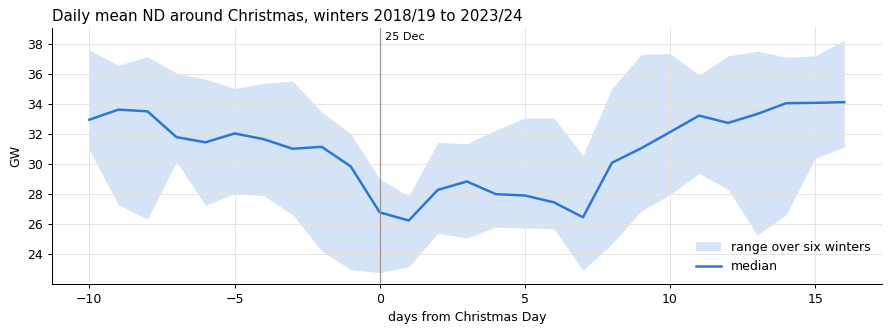

,15-21 Dec,27-31 Dec,6-10 Jan,27-31 Dec vs 15-21 Dec
winter,,,,
2018/19,34672.0,29788.0,35345.0,0.86
2019/20,34117.0,29608.0,33356.0,0.87
2020/21,30990.0,31389.0,35782.0,1.01
2021/22,33471.0,27925.0,33501.0,0.83
2022/23,32962.0,25972.0,28355.0,0.79
2023/24,29103.0,25788.0,32977.0,0.89


In [7]:
rows, windows = [], {}
for year in range(2018, 2024):
    window = daily.loc[f"{year}-12-15":f"{year + 1}-01-10", "ND"]
    windows[f"{year}/{str(year + 1)[2:]}"] = pd.Series(
        window.values, index=(window.index - pd.Timestamp(f"{year}-12-25")).days)
    rows.append({
        "winter": f"{year}/{str(year + 1)[2:]}",
        "15-21 Dec": window[:f"{year}-12-21"].mean(),
        "27-31 Dec": window[f"{year}-12-27":f"{year}-12-31"].mean(),
        "6-10 Jan": window[f"{year + 1}-01-06":].mean(),
    })
windows = pd.DataFrame(windows) / 1000

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(windows.index, windows.min(axis=1), windows.max(axis=1), color=BLUE, alpha=0.2,
                linewidth=0, label="range over six winters")
ax.plot(windows.index, windows.median(axis=1), color=BLUE, label="median")
ax.axvline(0, color="#999990", linewidth=1)
ax.annotate("25 Dec", (0, windows.max().max()), xytext=(4, 0), textcoords="offset points", fontsize=9)
ax.set_xlabel("days from Christmas Day")
ax.set_ylabel("GW")
ax.set_title("Daily mean ND around Christmas, winters 2018/19 to 2023/24", loc="left")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
plt.show()

christmas = pd.DataFrame(rows).set_index("winter").round(0)
christmas["27-31 Dec vs 15-21 Dec"] = (christmas["27-31 Dec"] / christmas["15-21 Dec"]).round(2)
christmas


**Found:**

- In most winters, the days between Christmas and New Year run 11% to 21% below the week of
  15 to 21 December, even though most of them are not bank holidays. Demand does not recover
  until around 6 to 8 January.
- 2020/21 is the exception: 27 to 31 December was no lower than mid-December. That winter had
  tighter COVID rules in December and may have been colder; Day 4's temperature data can check.
- The range band is wide: Christmas weeks differ a lot between years, so this will remain a
  hard period to forecast.

**Decision:** add a "Christmas period" feature (days from 25 December, for roughly 20 December
to 7 January) in addition to the bank holiday flag, and report errors for this period
separately on Day 8.


## Step 8. The 2020 lockdown

**What:** compare each week of 2020 with the same week of 2019, lined up 364 days apart so
weekdays match.

**Why:** the first lockdown started on 23 March 2020. A shock this large is not something the
model should learn as normal behaviour, so it needs handling. Weather also differed between the
two years, so small changes here mean little; only the large drop is clear.

**Further reading:** [Timeline of UK coronavirus lockdowns (Institute for Government)](https://www.instituteforgovernment.org.uk/data-visualisation/timeline-coronavirus-lockdowns)


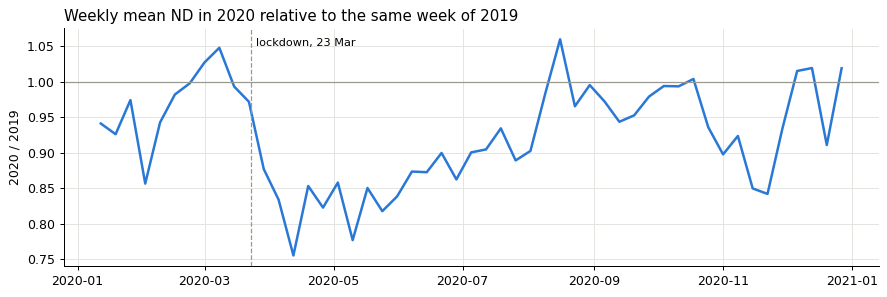

date
2020-03-01    1.027
2020-03-08    1.048
2020-03-15    0.993
2020-03-22    0.971
2020-03-29    0.877
2020-04-05    0.834
2020-04-12    0.755
2020-04-19    0.853
2020-04-26    0.823
2020-05-03    0.858
2020-05-10    0.777
2020-05-17    0.850
2020-05-24    0.818
2020-05-31    0.838
2020-06-07    0.873
2020-06-14    0.872
2020-06-21    0.899
2020-06-28    0.862
2020-07-05    0.900
2020-07-12    0.904
2020-07-19    0.934
2020-07-26    0.889
2020-08-02    0.902
2020-08-09    0.983
2020-08-16    1.059
2020-08-23    0.965
2020-08-30    0.995
Freq: W-SUN


In [8]:
year_on_year = (daily["ND"] / daily["ND"].shift(364)).loc["2020-01-06":"2020-12-27"]
weekly_ratio = year_on_year.resample("W").mean()

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(weekly_ratio.index, weekly_ratio.values, color=BLUE)
ax.axhline(1, color="#999990", linewidth=1)
ax.axvline(pd.Timestamp("2020-03-23"), color="#999990", linewidth=1, linestyle="--")
ax.annotate("lockdown, 23 Mar", (pd.Timestamp("2020-03-23"), 1.05), xytext=(4, 0),
            textcoords="offset points", fontsize=9)
ax.set_ylabel("2020 / 2019")
ax.set_title("Weekly mean ND in 2020 relative to the same week of 2019", loc="left")
fig.tight_layout()
plt.show()

print(weekly_ratio.loc["2020-03-01":"2020-08-31"].round(3).to_string())


**Found:**

- From the week of 29 March 2020, demand was 12% to 25% below the same week of 2019, with the
  lowest point in mid-April.
- It recovered slowly: about 10% below in June and July, and close to normal by September.
- There is a second dip in November 2020, during the second lockdown.
- The third lockdown (January to March 2021) is not covered by this chart.

**Decision:** keep 2020 and 2021 in the data but flag the lockdown periods. Day 6 will compare a
lockdown flag against leaving those periods out of training.


## Step 9. Embedded solar

**What:** in summer at midday, plot `ND` against NESO's estimate of embedded solar generation.

**Why:** notebook 02 found NESO's errors peak at midday. Embedded solar is not metered by the
transmission network, so every MW it produces is a MW less of `ND`. If that is right, the slope
should be close to −1, and a solar forecast error would turn into a demand error of about the
same size.

**Note:** `EMBEDDED_SOLAR_GENERATION` is itself an estimate (NESO's, based on models such as
Sheffield Solar's [PV_Live](https://www.solar.sheffield.ac.uk/pvlive/)), and it is the actual
outturn, so it is not available a day ahead. Day 4 replaces it with forecast weather.


      slope (MW per MW)  correlation
year                                
2018              -0.85        -0.73
2019              -0.88        -0.78
2020              -1.16        -0.86
2021              -0.82        -0.71
2022              -0.83        -0.70
2023              -0.82        -0.83
2024              -0.97        -0.85


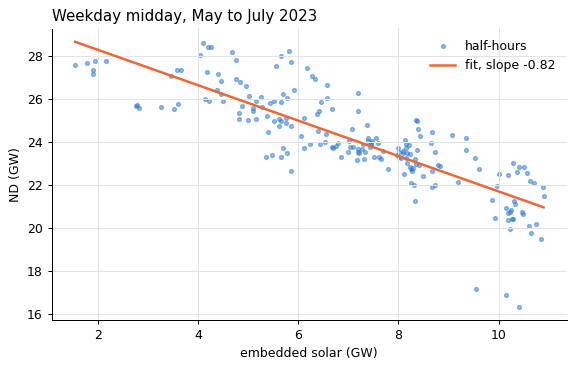

In [9]:
midday = demand[(demand["local_hour"] >= 12) & (demand["local_hour"] < 13.5)
                & demand["month"].isin([5, 6, 7]) & (demand["weekday"] < 5)]

fits = midday.groupby("year").apply(lambda g: pd.Series({
    "slope (MW per MW)": np.polyfit(g["EMBEDDED_SOLAR_GENERATION"], g["ND"], 1)[0],
    "correlation": g["ND"].corr(g["EMBEDDED_SOLAR_GENERATION"]),
}), include_groups=False).round(2)
print(fits.to_string())

latest = midday[midday["year"] == 2023]
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(latest["EMBEDDED_SOLAR_GENERATION"] / 1000, latest["ND"] / 1000, s=10, color=BLUE, alpha=0.5,
           label="half-hours")
slope, intercept = np.polyfit(latest["EMBEDDED_SOLAR_GENERATION"], latest["ND"], 1)
x = np.linspace(latest["EMBEDDED_SOLAR_GENERATION"].min(), latest["EMBEDDED_SOLAR_GENERATION"].max(), 2)
ax.plot(x / 1000, (slope * x + intercept) / 1000, color=ORANGE, label=f"fit, slope {slope:.2f}")
ax.set_xlabel("embedded solar (GW)")
ax.set_ylabel("ND (GW)")
ax.set_title("Weekday midday, May to July 2023", loc="left")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


**Found:**

- In most years each MW of embedded solar goes with 0.82 to 0.97 MW less `ND` at midday in
  summer (1.16 in 2020, when the lockdown also cut demand on sunny spring days). The
  correlation is −0.70 to −0.86.
- So the solar effect is close to one for one, as the definition of `ND` suggests. A
  forecast that gets the sunshine wrong by 2 GW of solar will get demand wrong by about 2 GW.
- This matches notebook 02's worst day, a large midday under-forecast.

**Decision:** the most useful feature for midday is a day-ahead estimate of embedded solar:
forecast solar radiation, scaled by NESO's embedded solar capacity (13.1 GW in 2018, 17.5 GW by
2024; see Step 10's table). Day 4 builds it.


## Step 10. Embedded wind

**What:** the same check for embedded wind, across all months and hours.

**Why:** embedded wind is hidden from `ND` the same way, but wind blows at any hour and more in
winter, when demand is also high. So the season gets in the way of a simple fit. Comparing
within each month removes most of that.


In [10]:
def within_month_slope(frame, column):
    centred = frame[[column, "ND"]] - frame.groupby(["year", "month", "local_hour"])[[column, "ND"]].transform("mean")
    return np.polyfit(centred[column], centred["ND"], 1)[0]


evening = demand[demand["weekday"] < 5]
print("ND vs embedded wind, within year, month and time of day:",
      round(within_month_slope(evening, "EMBEDDED_WIND_GENERATION"), 2), "MW per MW")
print("ND vs embedded solar, same method:",
      round(within_month_slope(evening, "EMBEDDED_SOLAR_GENERATION"), 2), "MW per MW")
print()
print(demand.groupby("year")[["EMBEDDED_WIND_CAPACITY", "EMBEDDED_SOLAR_CAPACITY"]].max().round(0).to_string())


ND vs embedded wind, within year, month and time of day: -0.88 MW per MW
ND vs embedded solar, same method: -1.03 MW per MW

      EMBEDDED_WIND_CAPACITY  EMBEDDED_SOLAR_CAPACITY
year                                                 
2018                    5978                    13052
2019                    6465                    13040
2020                    6559                    13471
2021                    6527                    14008
2022                    6574                    15037
2023                    6545                    16793
2024                    6562                    17511


**Found:**

- After taking out the year, month and time of day, each MW of embedded wind goes with about
  0.88 MW less `ND`. The same method gives 1.03 for solar, which supports Step 9.
- Embedded wind capacity has been almost flat since 2019, at about 6.5 GW, while solar capacity
  grew by a third.

**Decision:** add forecast wind speed (Day 4). Because wind capacity is flat, wind speed alone
may be enough. Solar needs capacity scaling.


## Step 11. How much does past demand tell us?

**What:** the correlation between demand and demand 1, 2, 3, 7 and 14 days earlier, at the same
half-hour.

**Why:** the plan only allows demand from two or more days before the target day (NESO's data
is published with a delay; Day 4 checks whether a live source exists). This shows how much that
rule costs compared with using yesterday.

**Further reading:** [Forecasting: Principles and Practice, section 2.8, autocorrelation](https://otexts.com/fpp3/acf.html)


In [11]:
series = demand.set_index("start_utc")["ND"]
lags = {}
for days in [1, 2, 3, 7, 14]:
    shifted = series.shift(freq=pd.Timedelta(days=days))
    lags[days] = series.corr(shifted.reindex(series.index))
pd.Series(lags, name="correlation").rename_axis("lag (days)").round(3).to_frame()


,correlation
lag (days),
1,0.915
2,0.840
3,0.815
7,0.911
14,0.879


**Found:**

- Demand one day earlier correlates 0.915 with the target. Two days earlier drops to 0.840,
  because the day two before is often a different kind of day (a Saturday before a Monday).
- **Seven days earlier correlates 0.911, almost as well as one day.** Same weekday, same time.
- So the two-day rule costs little, as long as the model gets the value from a week before.

**Note:** the shift here is in UTC, so in the week after a clock change the "same half-hour" is
an hour out. It has little effect on these figures, but the features on Day 6 should be built in
local time.

**Decision:** lag features at 7 and 14 days, plus the latest available day (two days before)
and a rolling weekly mean ending two days before.


## Summary and what it means for the model

**What drives GB demand**

| Pattern | Size | Feature for the model |
|---|---|---|
| Long-term fall | `ND` −4.1 GW in five years | recent lags carry the level; test training windows on Day 6 |
| Winter vs summer | about +38% | temperature and daylight (Day 4), day of year |
| Weekend | Saturday −11%, Sunday −12.5% | day of week (7 levels) |
| Bank holidays | −7% to −16% | holiday flag |
| Christmas to New Year | −11% to −21% | Christmas period feature |
| 2020 lockdown | down to −25% | lockdown flag, or leave out |
| Embedded solar | about −1 MW per MW, midday | forecast radiation × solar capacity (Day 4) |
| Embedded wind | about −0.9 MW per MW | forecast wind speed (Day 4) |
| Recent demand | lag 7 days, correlation 0.91 | lags at 2, 7 and 14 days |

**The main point:** the calendar explains the shape of a typical day, but the error NESO makes
is at midday, and that depends on sunshine. Getting good day-ahead solar information is the
best chance to do better than NESO.

**Next (Day 4):** fetch day-ahead weather forecasts for several GB locations, compare them with
what actually happened, build the solar and temperature features, and fix the information
cut-off rules.
